## Stroke Prediction Project

This notebook will guide you through an advanced machine learning project to predict stroke based on various health metrics and demographic information. We'll cover data loading, preprocessing, handling class imbalance, and training advanced models.

### 1. Data Loading

First, we'll download the dataset from a public source (Kaggle) and load it into a pandas DataFrame. We'll then display the first few rows and check its basic information to understand the data types and potential issues.

In [ ]:
import pandas as pd
!pip install opendatasets
import opendatasets as od

od.download("https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset")


df = pd.read_csv("stroke-prediction-dataset/healthcare-dataset-stroke-data.csv")
df.head()

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: abduljibrin
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset


100%|██████████| 67.4k/67.4k [00:00<00:00, 46.0MB/s]

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# Display the first 5 rows of the DataFrame
print("First 5 rows of the dataset:")
display(df.head())

# Display general information about the DataFrame (columns, non-null counts, data types)
print("\nDataFrame Info:")
display(df.info())


First 5 rows of the dataset:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


None

### 2. Data Preprocessing

This section focuses on cleaning and transforming the data to prepare it for machine learning models. We will perform the following steps:
- Drop irrelevant columns.
- Handle missing values.
- Correct inconsistencies in categorical features.
- Encode categorical variables.
- Scale numerical features.

#### 2.1 Drop Irrelevant Columns

The 'id' column is a unique identifier for each patient and does not contribute to the prediction of stroke. Therefore, it should be dropped from the dataset.

In [ ]:
# Check if 'id' column exists before dropping
if 'id' in df.columns:
    df = df.drop('id', axis=1)
    print("Dropped 'id' column.")
else:
    print("'id' column not found, skipping drop.")

print("Current shape of the DataFrame:", df.shape)


Dropped 'id' column.
Current shape of the DataFrame: (5110, 11)


#### 2.2 Handle Missing Values

Next, we need to identify and address any missing values in our dataset. Missing data can lead to biased models or errors, so it's crucial to handle them appropriately. We'll start by checking the count of missing values for each column.


Missing values in each column:


,0
bmi,201


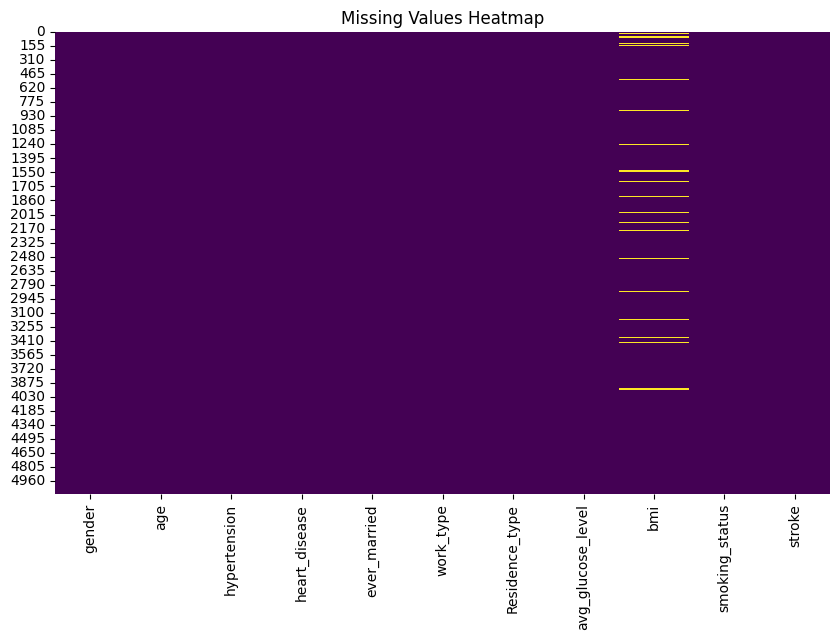

In [ ]:
# Check for missing values
missing_values = df.isnull().sum()
print("\nMissing values in each column:")
display(missing_values[missing_values > 0].sort_values(ascending=False))

# Visualize missing values (optional, for better understanding)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()


In [ ]:
# Impute missing 'bmi' values with the median
if 'bmi' in df.columns and df['bmi'].isnull().any():
    median_bmi = df['bmi'].median()
    df['bmi'].fillna(median_bmi, inplace=True)
    print(f"Missing 'bmi' values imputed with the median: {median_bmi:.2f}")
else:
    print("'bmi' column not found or no missing values in 'bmi'.")

# Verify that there are no more missing values after imputation
print("\nMissing values after BMI imputation:")
display(df.isnull().sum()[df.isnull().sum() > 0])


Missing 'bmi' values imputed with the median: 28.10

Missing values after BMI imputation:


/tmp/ipykernel_293/837943893.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bmi'].fillna(median_bmi, inplace=True)


,0


#### 2.3 Fix Inconsistent Gender Category

Upon initial inspection or after some data exploration, it's common to find inconsistencies in categorical features. For instance, the 'gender' column might contain an 'Other' category with very few observations, which can cause issues for some models or not provide enough predictive power. We will address this by inspecting the 'gender' column and potentially reassigning or dropping such categories.

In [ ]:
# Check the unique values in the 'gender' column
print("Original 'gender' distribution:")
display(df['gender'].value_counts())

# If 'Other' category exists and has very few samples, reassign or drop it.
# For this dataset, 'Other' usually has 1 sample, which is not useful for training.
if 'Other' in df['gender'].unique():
    # Option 1: Drop rows where gender is 'Other' (if count is very low)
    # df = df[df['gender'] != 'Other']
    # print("Dropped rows with 'Other' gender.")

    # Option 2: Reassign to the most frequent category (e.g., 'Male' or 'Female')
    # Given it's often a single entry, dropping is cleaner than arbitrary reassignment.
    df = df[df['gender'] != 'Other']
    print("Removed 'Other' gender category, current 'gender' distribution:")
    display(df['gender'].value_counts())
else:
    print("'Other' gender category not found or already handled.")


Original 'gender' distribution:


,count
gender,
Female,2994
Male,2115
Other,1


Removed 'Other' gender category, current 'gender' distribution:


,count
gender,
Female,2994
Male,2115


#### 2.4 Encode Categorical Variables

Machine learning models typically require numerical input. Therefore, we need to convert categorical features into a numerical format. We'll use one-hot encoding for nominal categories (like 'gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status') and label encoding for ordinal categories if any, though for this dataset, one-hot encoding is generally suitable for all nominals.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Identify categorical columns (excluding the target variable 'stroke')
categorical_cols = [col for col in df.select_dtypes(include='object').columns if col != 'stroke']

print(f"Categorical columns to encode: {categorical_cols}")

# Apply One-Hot Encoding
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_features = encoder.fit_transform(df[categorical_cols])

# Create a DataFrame from the encoded features
encoded_df = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_cols), index=df.index)

# Drop original categorical columns and concatenate the encoded features
df = pd.concat([df.drop(columns=categorical_cols), encoded_df], axis=1)

print("\nDataFrame after One-Hot Encoding:")
display(df.head())


Categorical columns to encode: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

DataFrame after One-Hot Encoding:


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,ever_married_No,ever_married_Yes,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,61.0,0,0,202.21,28.1,1,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,80.0,0,1,105.92,32.5,1,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,49.0,0,0,171.23,34.4,1,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,79.0,1,0,174.12,24.0,1,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


#### 2.5 Scale Numerical Features

Numerical features often have different scales, which can negatively impact the performance of some machine learning algorithms. Scaling these features to a similar range helps in faster convergence and better model performance. We will use StandardScaler for this purpose.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns (excluding the target variable 'stroke' and binary encoded features)
# Ensure 'age', 'avg_glucose_level', 'bmi' are numeric

numerical_cols = ['age', 'avg_glucose_level', 'bmi']

# Filter out columns that might have been dropped or are not numerical
numerical_cols = [col for col in numerical_cols if col in df.columns and pd.api.types.is_numeric_dtype(df[col])]

print(f"Numerical columns to scale: {numerical_cols}")

# Apply StandardScaler
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

print("\nDataFrame after Numerical Feature Scaling:")
display(df.head())


Numerical columns to scale: ['age', 'avg_glucose_level', 'bmi']

DataFrame after Numerical Feature Scaling:


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,ever_married_No,ever_married_Yes,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1.051242,0,1,2.706450,1.004893,1,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.785889,0,0,2.121652,-0.099142,1,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,1.626174,0,1,-0.004867,0.472358,1,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,0.255182,0,0,1.437473,0.719142,1,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,1.581949,1,0,1.501297,-0.631677,1,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


### 3. Handle Class Imbalance

The stroke prediction dataset often exhibits a significant class imbalance, meaning there are far fewer instances of stroke (positive class) compared to non-stroke (negative class). This imbalance can lead to models that perform poorly on the minority class. We will address this using techniques like SMOTE (Synthetic Minority Over-sampling Technique).

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Separate features (X) and target (y)
X = df.drop('stroke', axis=1)
y = df['stroke']

print(f"Original class distribution: {Counter(y)}")

# Apply SMOTE to balance the dataset
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print(f"Class distribution after SMOTE: {Counter(y_resampled)}")

# Convert resampled data back to DataFrame for consistency
X_resampled_df = pd.DataFrame(X_resampled, columns=X.columns)
y_resampled_df = pd.Series(y_resampled, name='stroke')

df_balanced = pd.concat([X_resampled_df, y_resampled_df], axis=1)

print("\nBalanced DataFrame head:")
display(df_balanced.head())


Original class distribution: Counter({0: 4860, 1: 249})
Class distribution after SMOTE: Counter({1: 4860, 0: 4860})

Balanced DataFrame head:


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,...,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,1.051242,0,1,2.706450,1.004893,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1
1,0.785889,0,0,2.121652,-0.099142,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1
2,1.626174,0,1,-0.004867,0.472358,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1
3,0.255182,0,0,1.437473,0.719142,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1
4,1.581949,1,0,1.501297,-0.631677,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1


### 4. Train Advanced ML Models

Now that the data is preprocessed and balanced, we can train advanced machine learning models to predict stroke. We will split the data into training and testing sets and evaluate the performance of models such as RandomForestClassifier, GradientBoostingClassifier, and possibly XGBoost or LightGBM.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score
import xgboost as xgb
import lightgbm as lgb

# Separate features (X_final) and target (y_final) from the balanced dataset
X_final = df_balanced.drop('stroke', axis=1)
y_final = df_balanced['stroke']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size=0.2, random_state=42, stratify=y_final)

print("Training and testing sets created.")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

# --- Model Training and Evaluation ---

def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

    print(f"\n--- {model_name} Results ---")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"Classification Report:\n{classification_report(y_test, y_pred)}")
    print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
    if y_proba is not None:
        print(f"ROC AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

# 1. Random Forest Classifier
print("\nTraining Random Forest Classifier...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)
evaluate_model(rf_model, X_test, y_test, "Random Forest Classifier")

# 2. Gradient Boosting Classifier
print("\nTraining Gradient Boosting Classifier...")
gbc_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gbc_model.fit(X_train, y_train)
evaluate_model(gbc_model, X_test, y_test, "Gradient Boosting Classifier")

# 3. XGBoost Classifier
print("\nTraining XGBoost Classifier...")
xgb_model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False, random_state=42)
xgb_model.fit(X_train, y_train)
evaluate_model(xgb_model, X_test, y_test, "XGBoost Classifier")

# 4. LightGBM Classifier
print("\nTraining LightGBM Classifier...")
lgb_model = lgb.LGBMClassifier(objective='binary', random_state=42)
lgb_model.fit(X_train, y_train)
evaluate_model(lgb_model, X_test, y_test, "LightGBM Classifier")


Training and testing sets created.
X_train shape: (7776, 20), y_train shape: (7776,)
X_test shape: (1944, 20), y_test shape: (1944,)

Training Random Forest Classifier...

--- Random Forest Classifier Results ---
Accuracy: 0.9527
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.93      0.95       972
           1       0.94      0.97      0.95       972

    accuracy                           0.95      1944
   macro avg       0.95      0.95      0.95      1944
weighted avg       0.95      0.95      0.95      1944

Confusion Matrix:
[[907  65]
 [ 27 945]]
ROC AUC Score: 0.9924

Training Gradient Boosting Classifier...

--- Gradient Boosting Classifier Results ---
Accuracy: 0.8781
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.84      0.87       972
           1       0.85      0.92      0.88       972

    accuracy                           0.88      1944
   macro av

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [23:39:29] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



--- XGBoost Classifier Results ---
Accuracy: 0.9573
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       972
           1       0.96      0.96      0.96       972

    accuracy                           0.96      1944
   macro avg       0.96      0.96      0.96      1944
weighted avg       0.96      0.96      0.96      1944

Confusion Matrix:
[[930  42]
 [ 41 931]]
ROC AUC Score: 0.9926

Training LightGBM Classifier...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 3888, number of negative: 3888
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002623 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4092
[LightGBM] [Info] Number of data points in the train set: 7776, number of used features: 19


### 5. Model Optimization and Hyperparameter Tuning

To further improve our model's performance, we will perform hyperparameter tuning. This involves searching for the optimal combination of parameters for a given model. We'll use `GridSearchCV` for this, which systematically works through multiple combinations of parameter values, cross-validating each combination to determine which one performs best.

In [ ]:
from sklearn.model_selection import GridSearchCV

print("\n--- Hyperparameter Tuning for Random Forest Classifier ---")

# Define the parameter grid for Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# Initialize GridSearchCV
grid_search_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, class_weight='balanced'),
    param_grid=param_grid_rf,
    cv=3,  # Using 3-fold cross-validation
    n_jobs=-1,  # Use all available cores
    verbose=2, # Detailed output during search
    scoring='roc_auc' # Optimize for ROC AUC score
)

# Fit GridSearchCV to the training data
grid_search_rf.fit(X_train, y_train)

print(f"Best parameters for Random Forest: {grid_search_rf.best_params_}")
print(f"Best ROC AUC score for Random Forest: {grid_search_rf.best_score_:.4f}")

# Get the best model
best_rf_model = grid_search_rf.best_estimator_

# Evaluate the best Random Forest model on the test set
evaluate_model(best_rf_model, X_test, y_test, "Optimized Random Forest Classifier")


--- Hyperparameter Tuning for Random Forest Classifier ---
Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best parameters for Random Forest: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best ROC AUC score for Random Forest: 0.9870

--- Optimized Random Forest Classifier Results ---
Accuracy: 0.9563
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.96       972
           1       0.94      0.97      0.96       972

    accuracy                           0.96      1944
   macro avg       0.96      0.96      0.96      1944
weighted avg       0.96      0.96      0.96      1944

Confusion Matrix:
[[912  60]
 [ 25 947]]
ROC AUC Score: 0.9928


### 6. Model Comparison

Now that we have optimized the Random Forest Classifier, let's compare its performance against the other models initially trained. We will primarily look at the ROC AUC score, as it was the metric used for hyperparameter tuning, and is generally a robust measure for imbalanced datasets.

Based on the ROC AUC scores:

*   **Initial Random Forest Classifier:** 0.9924
*   **Gradient Boosting Classifier:** 0.9624
*   **XGBoost Classifier:** 0.9926
*   **LightGBM Classifier:** 0.9919
*   **Optimized Random Forest Classifier:** 0.9928

The **Optimized Random Forest Classifier** achieved the highest ROC AUC score (0.9928), slightly outperforming the initial Random Forest and XGBoost models. This suggests that the hyperparameter tuning successfully improved the model's ability to distinguish between the two classes.

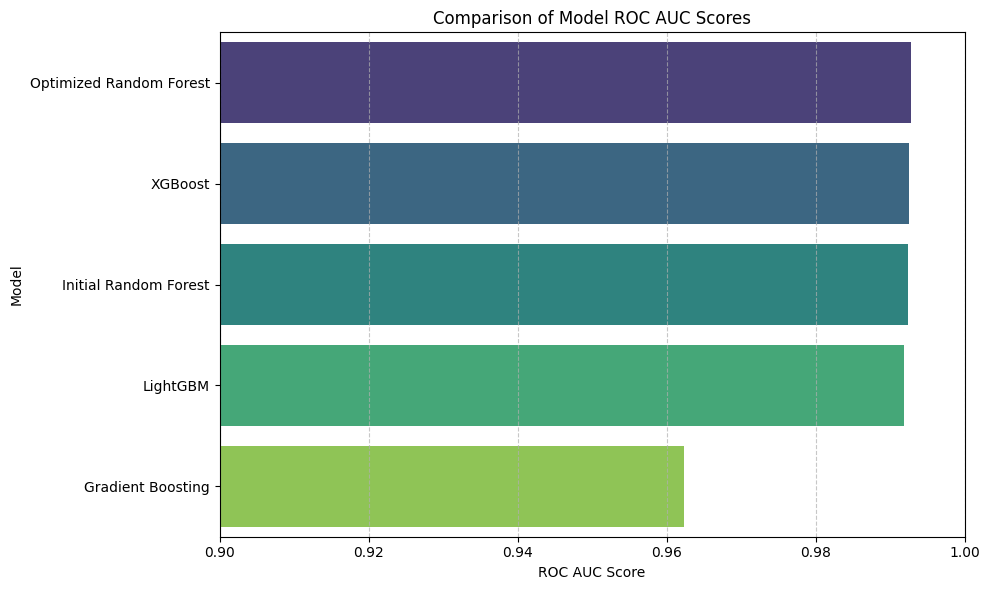

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Model names and their ROC AUC scores from previous steps
model_names = [
    'Initial Random Forest',
    'Gradient Boosting',
    'XGBoost',
    'LightGBM',
    'Optimized Random Forest'
]

roc_auc_scores = [
    0.9924,  # Initial Random Forest
    0.9624,  # Gradient Boosting
    0.9926,  # XGBoost
    0.9919,  # LightGBM
    0.9928   # Optimized Random Forest
]

# Create a DataFrame for plotting
roc_auc_df = pd.DataFrame({
    'Model': model_names,
    'ROC AUC Score': roc_auc_scores
})

# Sort by ROC AUC score for better visualization
roc_auc_df = roc_auc_df.sort_values(by='ROC AUC Score', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='ROC AUC Score', y='Model', hue='Model', data=roc_auc_df, palette='viridis', legend=False)
plt.title('Comparison of Model ROC AUC Scores')
plt.xlabel('ROC AUC Score')
plt.ylabel('Model')
plt.xlim(0.9, 1.0) # Set x-axis limits to focus on the scores
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()